import libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

Load Dataset

In [6]:
df = pd.read_csv("FakeNewsNet.csv")

df.head(2)

,title,news_url,source_domain,tweet_num,real
0,Kandi Burruss Explodes Over Rape Accusation on...,http://toofab.com/2017/05/08/real-housewives-a...,toofab.com,42,1
1,People's Choice Awards 2018: The best red carp...,https://www.today.com/style/see-people-s-choic...,www.today.com,0,1


remove missing values

In [7]:

df.isnull().sum()
df = df.dropna(subset=['title', 'real'])

split data

In [9]:
X = df['title']
y = df['real']
print(y.value_counts())

real
1    17441
0     5755
Name: count, dtype: int64


train-test split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

TF-IDF Conversion

In [12]:
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=2000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training Shape:", X_train_tfidf.shape)
print("Testing Shape:", X_test_tfidf.shape)

Training Shape: (18556, 2000)
Testing Shape: (4640, 2000)


TASK 1: Implement Bagging Techniques Using Random Forest

train random forest model

In [13]:
rf_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

rf_model.fit(X_train_tfidf, y_train)

rf_time = time.time() - start_time

rf_pred = rf_model.predict(X_test_tfidf)

print("Random Forest Training Time:", rf_time)

Random Forest Training Time: 0.2691988945007324


Train Decision Tree for Comparison

In [14]:
dt_model = DecisionTreeClassifier(
    max_depth=20,
    random_state=42
)

dt_model.fit(X_train_tfidf, y_train)

dt_pred = dt_model.predict(X_test_tfidf)

Evaluate Random Forest and Decision Tree

In [15]:
models = {
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred
}

for name, pred in models.items():
    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred, zero_division=0))
    print("Recall:", recall_score(y_test, pred, zero_division=0))
    print("F1 Score:", f1_score(y_test, pred, zero_division=0))


 Decision Tree
Accuracy: 0.8125
Precision: 0.8237330037082818
Recall: 0.9550014330753798
F1 Score: 0.8845234934961508

 Random Forest
Accuracy: 0.7954741379310345
Precision: 0.7943903569772832
Recall: 0.9822298652909143
F1 Score: 0.8783801102140203


Random Forest Confusion Matrix

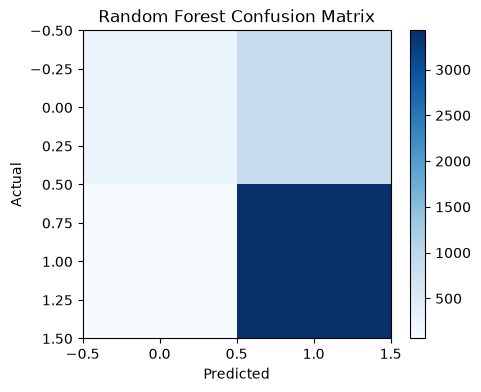

In [16]:
cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap='Blues')
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()
plt.show()

TASK 2: Implement Boosting Techniques Using XGBoost and LightGBM

Train XGBoost Model

In [17]:
xgb_model = XGBClassifier(
    n_estimators=50,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

start_time = time.time()

xgb_model.fit(X_train_tfidf, y_train)

xgb_time = time.time() - start_time

xgb_pred = xgb_model.predict(X_test_tfidf)

print("XGBoost Training Time:", xgb_time)

XGBoost Training Time: 0.9741418361663818


Train LightGBM Model

In [18]:
lgb_model = LGBMClassifier(
    n_estimators=50,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

start_time = time.time()

lgb_model.fit(X_train_tfidf, y_train)

lgb_time = time.time() - start_time

lgb_pred = lgb_model.predict(X_test_tfidf)

print("LightGBM Training Time:", lgb_time)

LightGBM Training Time: 0.30345988273620605


Evaluate Boosting Models

In [19]:
boosting_models = {
    "XGBoost": xgb_pred,
    "LightGBM": lgb_pred
}

for name, pred in boosting_models.items():
    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred, zero_division=0))
    print("Recall:", recall_score(y_test, pred, zero_division=0))
    print("F1 Score:", f1_score(y_test, pred, zero_division=0))


 XGBoost
Accuracy: 0.7959051724137931
Precision: 0.7936691312384473
Recall: 0.9845227858985383
F1 Score: 0.8788537802225918

 LightGBM
Accuracy: 0.7965517241379311
Precision: 0.7953121373868647
Recall: 0.9822298652909143
F1 Score: 0.8789433187996922


Hyperparameter Tuning Using Grid Search

In [20]:
param_grid = {
    'n_estimators': [30, 50],
    'max_depth': [3, 5],
    'learning_rate': [0.1]
}

grid_search = GridSearchCV(
    estimator=XGBClassifier(
        random_state=42,
        eval_metric='logloss',
        n_jobs=-1
    ),
    param_grid=param_grid,
    cv=2,
    scoring='accuracy',
    n_jobs=1,
    verbose=1
)

grid_search.fit(X_train_tfidf, y_train)

Fitting 2 folds for each of 4 candidates, totalling 8 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.1], 'max_depth': [3, 5], 'n_estimators': [30, 50]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",2
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py

Display Best Parameters

In [21]:
print("Best Parameters:", grid_search.best_params_)
print("Best Cross Validation Accuracy:", grid_search.best_score_)

Best Parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 50}
Best Cross Validation Accuracy: 0.7993101961629662


Evaluate Tuned XGBoost Model

In [22]:
best_xgb = grid_search.best_estimator_

best_xgb_pred = best_xgb.predict(X_test_tfidf)

print("Tuned XGBoost Accuracy:", accuracy_score(y_test, best_xgb_pred))
print("Tuned XGBoost Precision:", precision_score(y_test, best_xgb_pred, zero_division=0))
print("Tuned XGBoost Recall:", recall_score(y_test, best_xgb_pred, zero_division=0))
print("Tuned XGBoost F1 Score:", f1_score(y_test, best_xgb_pred, zero_division=0))

Tuned XGBoost Accuracy: 0.8073275862068966
Tuned XGBoost Precision: 0.8065201984408221
Tuned XGBoost Recall: 0.9785038693035254
Tuned XGBoost F1 Score: 0.8842268842268842


TASK 3: Implement Stacking Classifier

Create Base Models

In [23]:
base_models = [
    ('lr', LogisticRegression(max_iter=1000)),
    ('dt', DecisionTreeClassifier(max_depth=10, random_state=42)),
    ('svm', LinearSVC(random_state=42))
]

Create Stacking Classifier

In [24]:
stack_model = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(max_iter=1000),
    cv=2,
    n_jobs=-1
)

Train Stacking Model

In [25]:
start_time = time.time()

stack_model.fit(X_train_tfidf, y_train)

stack_time = time.time() - start_time

stack_pred = stack_model.predict(X_test_tfidf)

print("Stacking Training Time:", stack_time)

Stacking Training Time: 9.952651977539062


Evaluate Stacking Model

In [26]:
print("Stacking Classifier Results")

print("Accuracy:", accuracy_score(y_test, stack_pred))
print("Precision:", precision_score(y_test, stack_pred, zero_division=0))
print("Recall:", recall_score(y_test, stack_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, stack_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, stack_pred, zero_division=0))

Stacking Classifier Results
Accuracy: 0.8415948275862069
Precision: 0.8606600314300681
Recall: 0.941817139581542
F1 Score: 0.8994115231969344

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.54      0.63      1151
           1       0.86      0.94      0.90      3489

    accuracy                           0.84      4640
   macro avg       0.81      0.74      0.76      4640
weighted avg       0.83      0.84      0.83      4640



FINAL COMPARISON

In [27]:
all_models = {
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred,
    "LightGBM": lgb_pred,
    "Tuned XGBoost": best_xgb_pred,
    "Stacking": stack_pred
}

results = []

for name, pred in all_models.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0)
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.812500,0.823733,0.955001,0.884523
1,Random Forest,0.795474,0.794390,0.982230,0.878380
2,XGBoost,0.795905,0.793669,0.984523,0.878854
3,LightGBM,0.796552,0.795312,0.982230,0.878943
4,Tuned XGBoost,0.807328,0.806520,0.978504,0.884227
5,Stacking,0.841595,0.860660,0.941817,0.899412


Visualize Model Performance

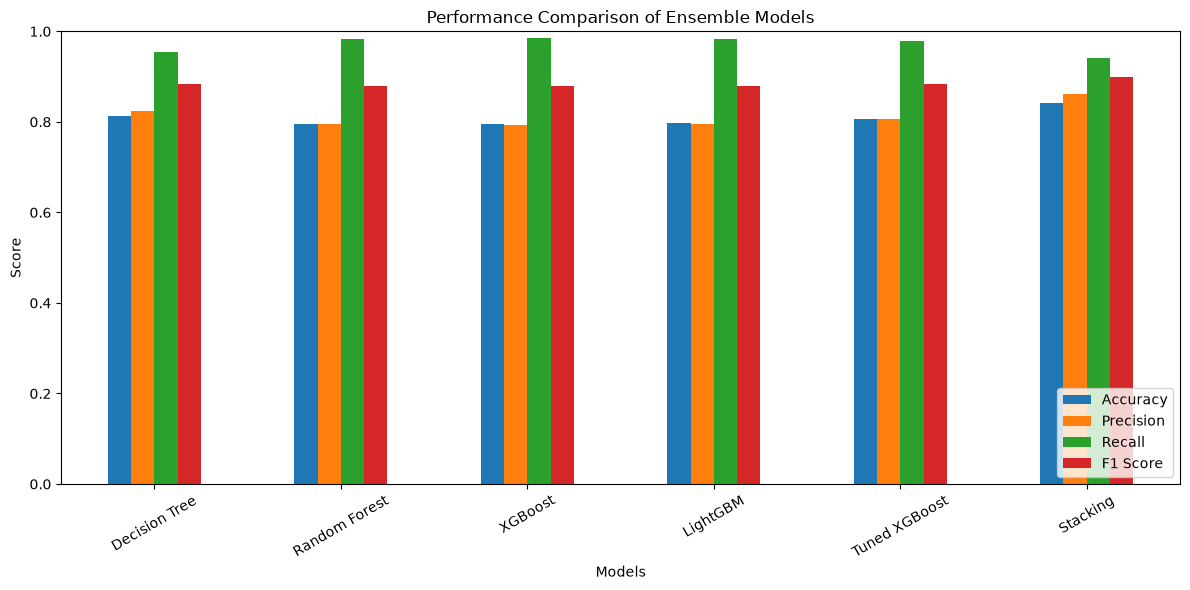

In [28]:
results_df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1 Score']].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Performance Comparison of Ensemble Models")
plt.ylabel("Score")
plt.xlabel("Models")
plt.xticks(rotation=30)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Find Best Performing Model

In [29]:
best_model = results_df.loc[results_df['Accuracy'].idxmax()]

print("Best Performing Model:")
print(best_model)

Best Performing Model:
Model        Stacking
Accuracy     0.841595
Precision     0.86066
Recall       0.941817
F1 Score     0.899412
Name: 5, dtype: object
